In [1]:
# import os
# import sys
import torch
import torch.nn as nn
# import torch.nn.functional as F
import torchvision.transforms as transforms
# from pathlib import Path
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

from utils.evaluate import evaluate
from unet import UNet

import numpy as np
import matplotlib.pyplot as plt

In [2]:
from fakeionogramdatasetOX import ParabolaIonoDatasetOX
from testionogramdataset import HandPickTraceDataset

In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)


cuda:0


In [27]:
from torch.optim import AdamW

# epochs = 10
batch_size = 5
# learning_rate = 1e-4
val_percent = 0.1

# weight_decay = 5e-3
# momentum = 0.2
# gradient_clipping = 1.0

target_size = [512,408] #[572,572] #[524,412]
original_size = [512,408]
resize = 'pad'

train_dataset = ParabolaIonoDatasetOX('training_data', target_size= target_size, resize=resize)

n_val = int(len(train_dataset) * val_percent)
n_train = len(train_dataset) - n_val
train_set, val_set = random_split(train_dataset, [n_train, n_val], generator=torch.Generator())

# 3. Create data loaders
loader_args = dict(batch_size=batch_size, num_workers=5, pin_memory=True) #os.cpu_count()

train_loader = DataLoader(train_set, shuffle=True, drop_last=True, **loader_args)

loader_args['batch_size'] = 5
val_loader = DataLoader(val_set, shuffle=True, drop_last=True, **loader_args)

test_dataset = HandPickTraceDataset('VIPIR_PROC/proc', 'VIPIR_PROC/dog_pick', target_size= target_size, resize=resize)
test_loader = DataLoader(test_dataset, shuffle=True, drop_last=True, **loader_args)


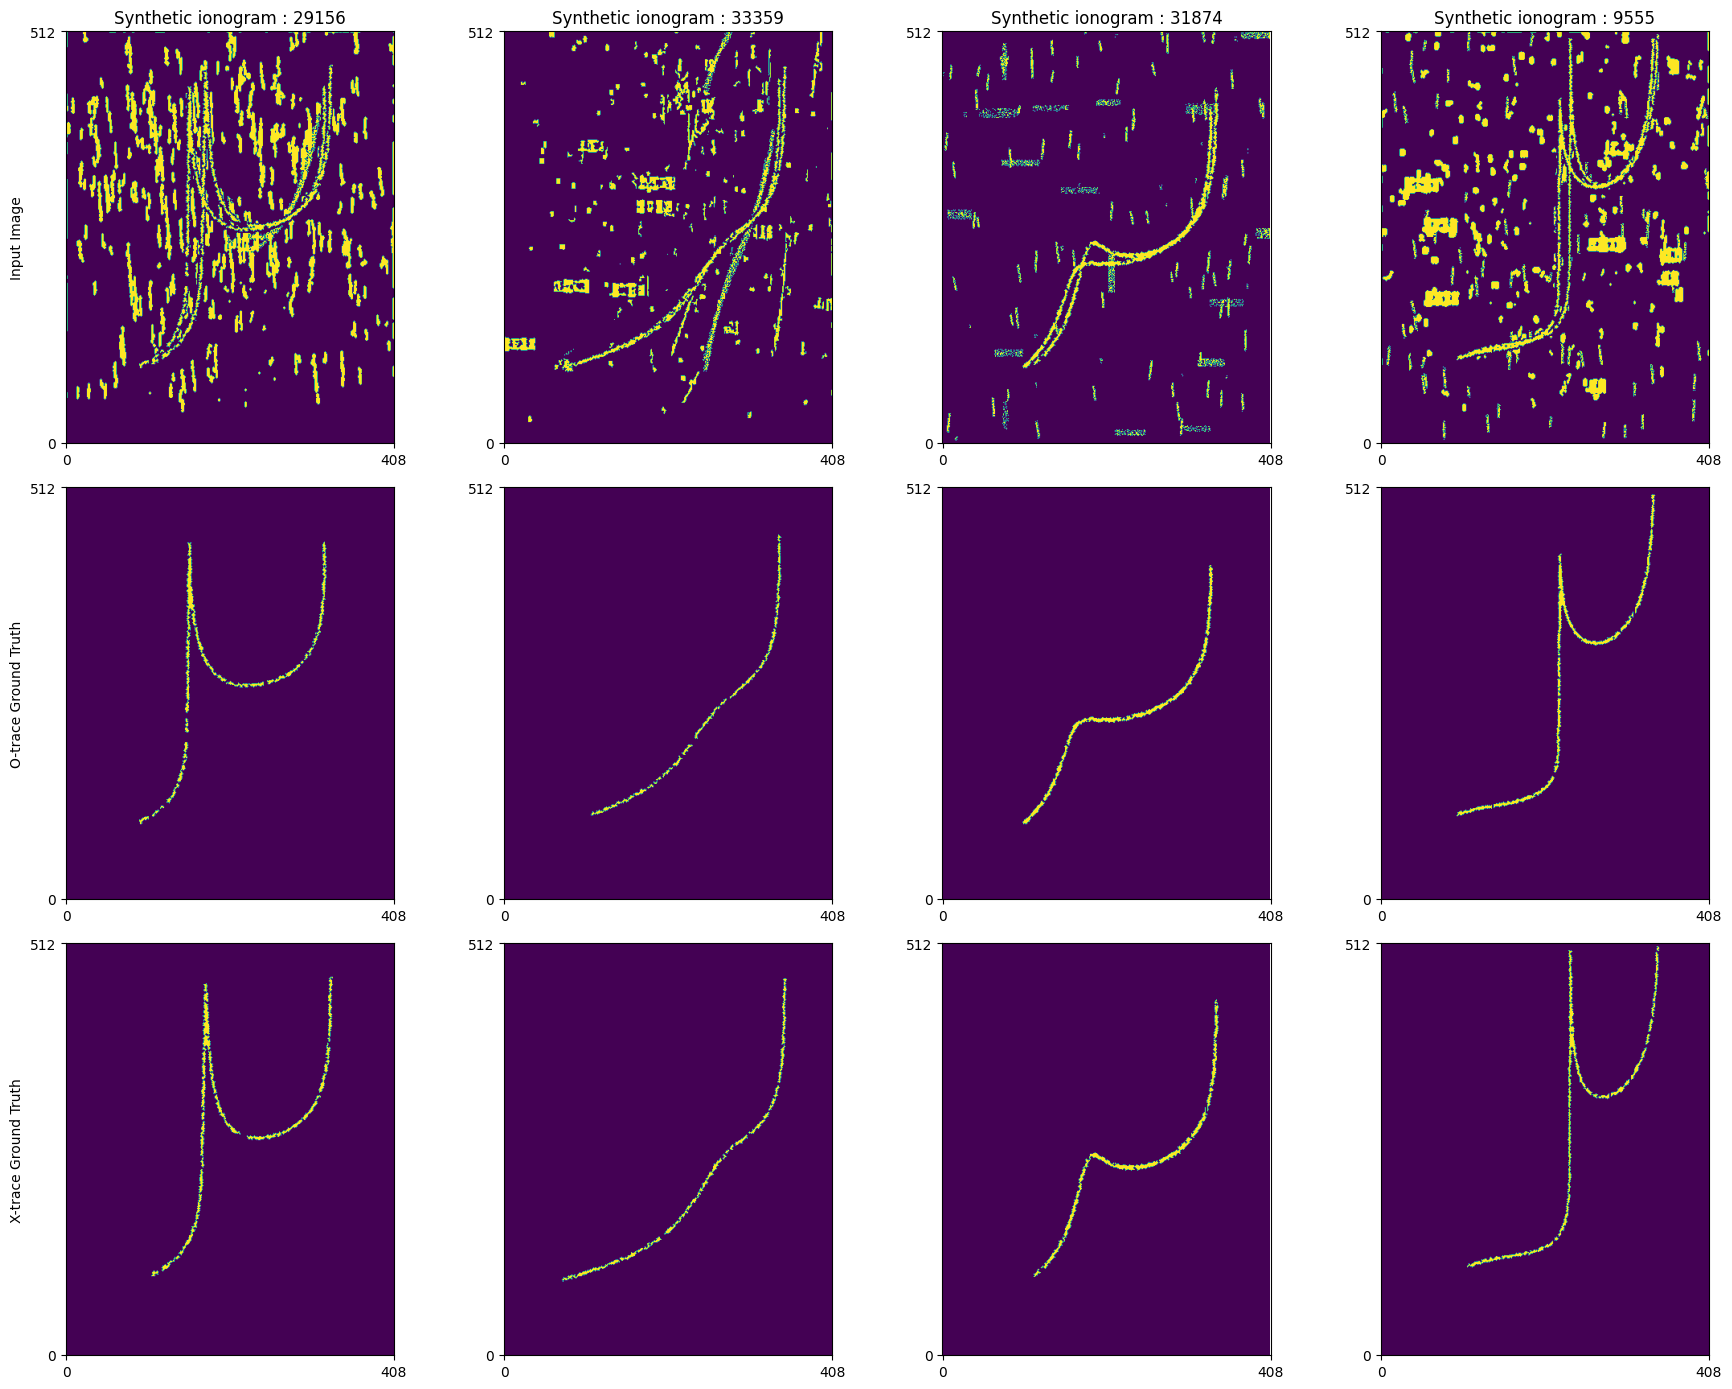

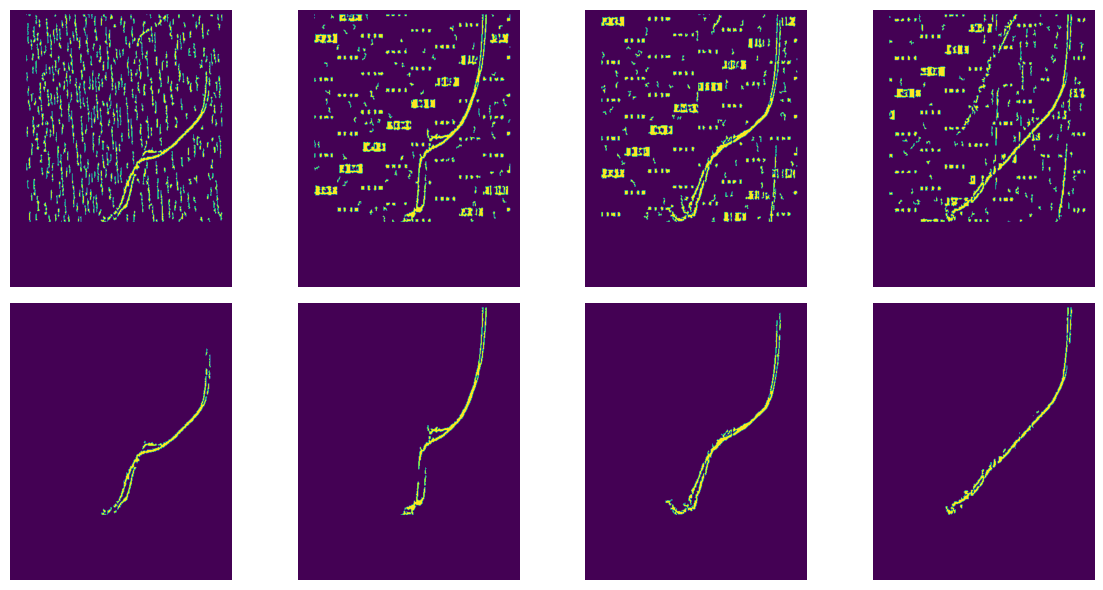

In [71]:
# visualize the training set

fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(18, 14))
for idx, ax_i in enumerate(axs.T):
    target = train_dataset[np.random.randint(0,len(train_dataset)-1)]
    img = target["image"]
    gt = target["mask"]
    filename = target["filename"]
    # print(filename.split('_'))
    ax = ax_i[0]
    img = img.permute((1, 2, 0)).numpy()
    ax.imshow((img), origin = 'lower')
    ax.set_yticks([0,512])
    ax.set_xticks([0,408])
    ax.set_title(f'Synthetic ionogram : {filename}')
    # ax.axis('off')
    ax = ax_i[1]
    gt = gt.numpy()
    ax.imshow((gt[0,:,:]).astype(np.uint8), origin = 'lower')
    ax.set_yticks([0,512])
    ax.set_xticks([0,408])
    # ax.axis('off')
    ax = ax_i[2]
    ax.imshow((gt[1,:,:]).astype(np.uint8), origin = 'lower')
    ax.set_yticks([0,512])
    ax.set_xticks([0,408])
    # ax.axis('off')
    if idx == 0:
        ax_i[0].set_ylabel('Input Image')
        ax_i[1].set_ylabel('O-trace Ground Truth')
        ax_i[2].set_ylabel('X-trace Ground Truth')
fig.tight_layout()
fig.savefig('traindata_set', bbox_inches = 0, dpi=300)

# visualize the test set

fig, axs = plt.subplots(ncols=4, nrows=2, figsize=(12, 6))
for idx, ax_i in enumerate(axs.T):
    target = test_dataset[idx]
    img = target["image"]
    gt = target["mask"]
    ax = ax_i[0]
    img = img.permute((1, 2, 0)).numpy()
    ax.imshow((img),aspect='equal' ,origin = 'lower')
    ax.axis('off')
    ax = ax_i[1]
    gt = gt.permute((1, 2, 0)).numpy()
    ax.imshow((gt).astype(np.uint8), aspect='equal', origin = 'lower')
    ax.axis('off')
fig.tight_layout()

In [11]:
class DBCEF(nn.Module):
    """ DBCEF from paper https://arxiv.org/pdf/1906.05229 """

    def __init__(self, epsilon: float = 1e-4, gamma: float = 1.0):
        super().__init__()
        self.softmax = nn.Softmax(dim=1)
        self.epsilon = epsilon
        self.gamma = gamma

    def forward(self, input : torch.Tensor, target : torch.Tensor):
        y = torch.clamp(self.softmax(input), min = 1e-10, max = 1-1e-10)
        t = nn.functional.one_hot(target, num_classes = 2).permute(0, 3, 1, 2).contiguous()

        N = t.size()[-1]*t.size()[-2]
        beta = torch.sum(t,dim=(-1,-2))/N + self.epsilon 
        beta = beta[:,:,None,None]

        CE = t*torch.clamp(torch.log(y), min = -100)
        FCE = (1-y)**self.gamma*CE
        # FCE = CE
        DBCEF = FCE/beta

        return -1*torch.sum(DBCEF)/N/y.size()[0]
    

In [10]:
target_size = [512,408]
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.3, dropout_p=0.3)

model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_12_25000_loss0.7506.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

/tmp/ipykernel_15849/2928834145.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_12_25000_loss0.7506

UNet(
  (att): Transformer(
    (in_linear): Linear(in_features=512, out_features=1024, bias=True)
    (out_linear): Linear(in_features=1024, out_features=1024, bias=True)
    (blocks): Sequential(
      (0): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=1024, out_features=1024, bias=True)
        )
        (relu): ReLU(inplace=True)
        (ln): GroupNorm(1, 408, eps=1e-05, affine=True)
      )
      (1): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj):

torch.Size([5, 1, 512, 408]) torch.Size([5, 2, 512, 408])
(5, 4, 512, 408)


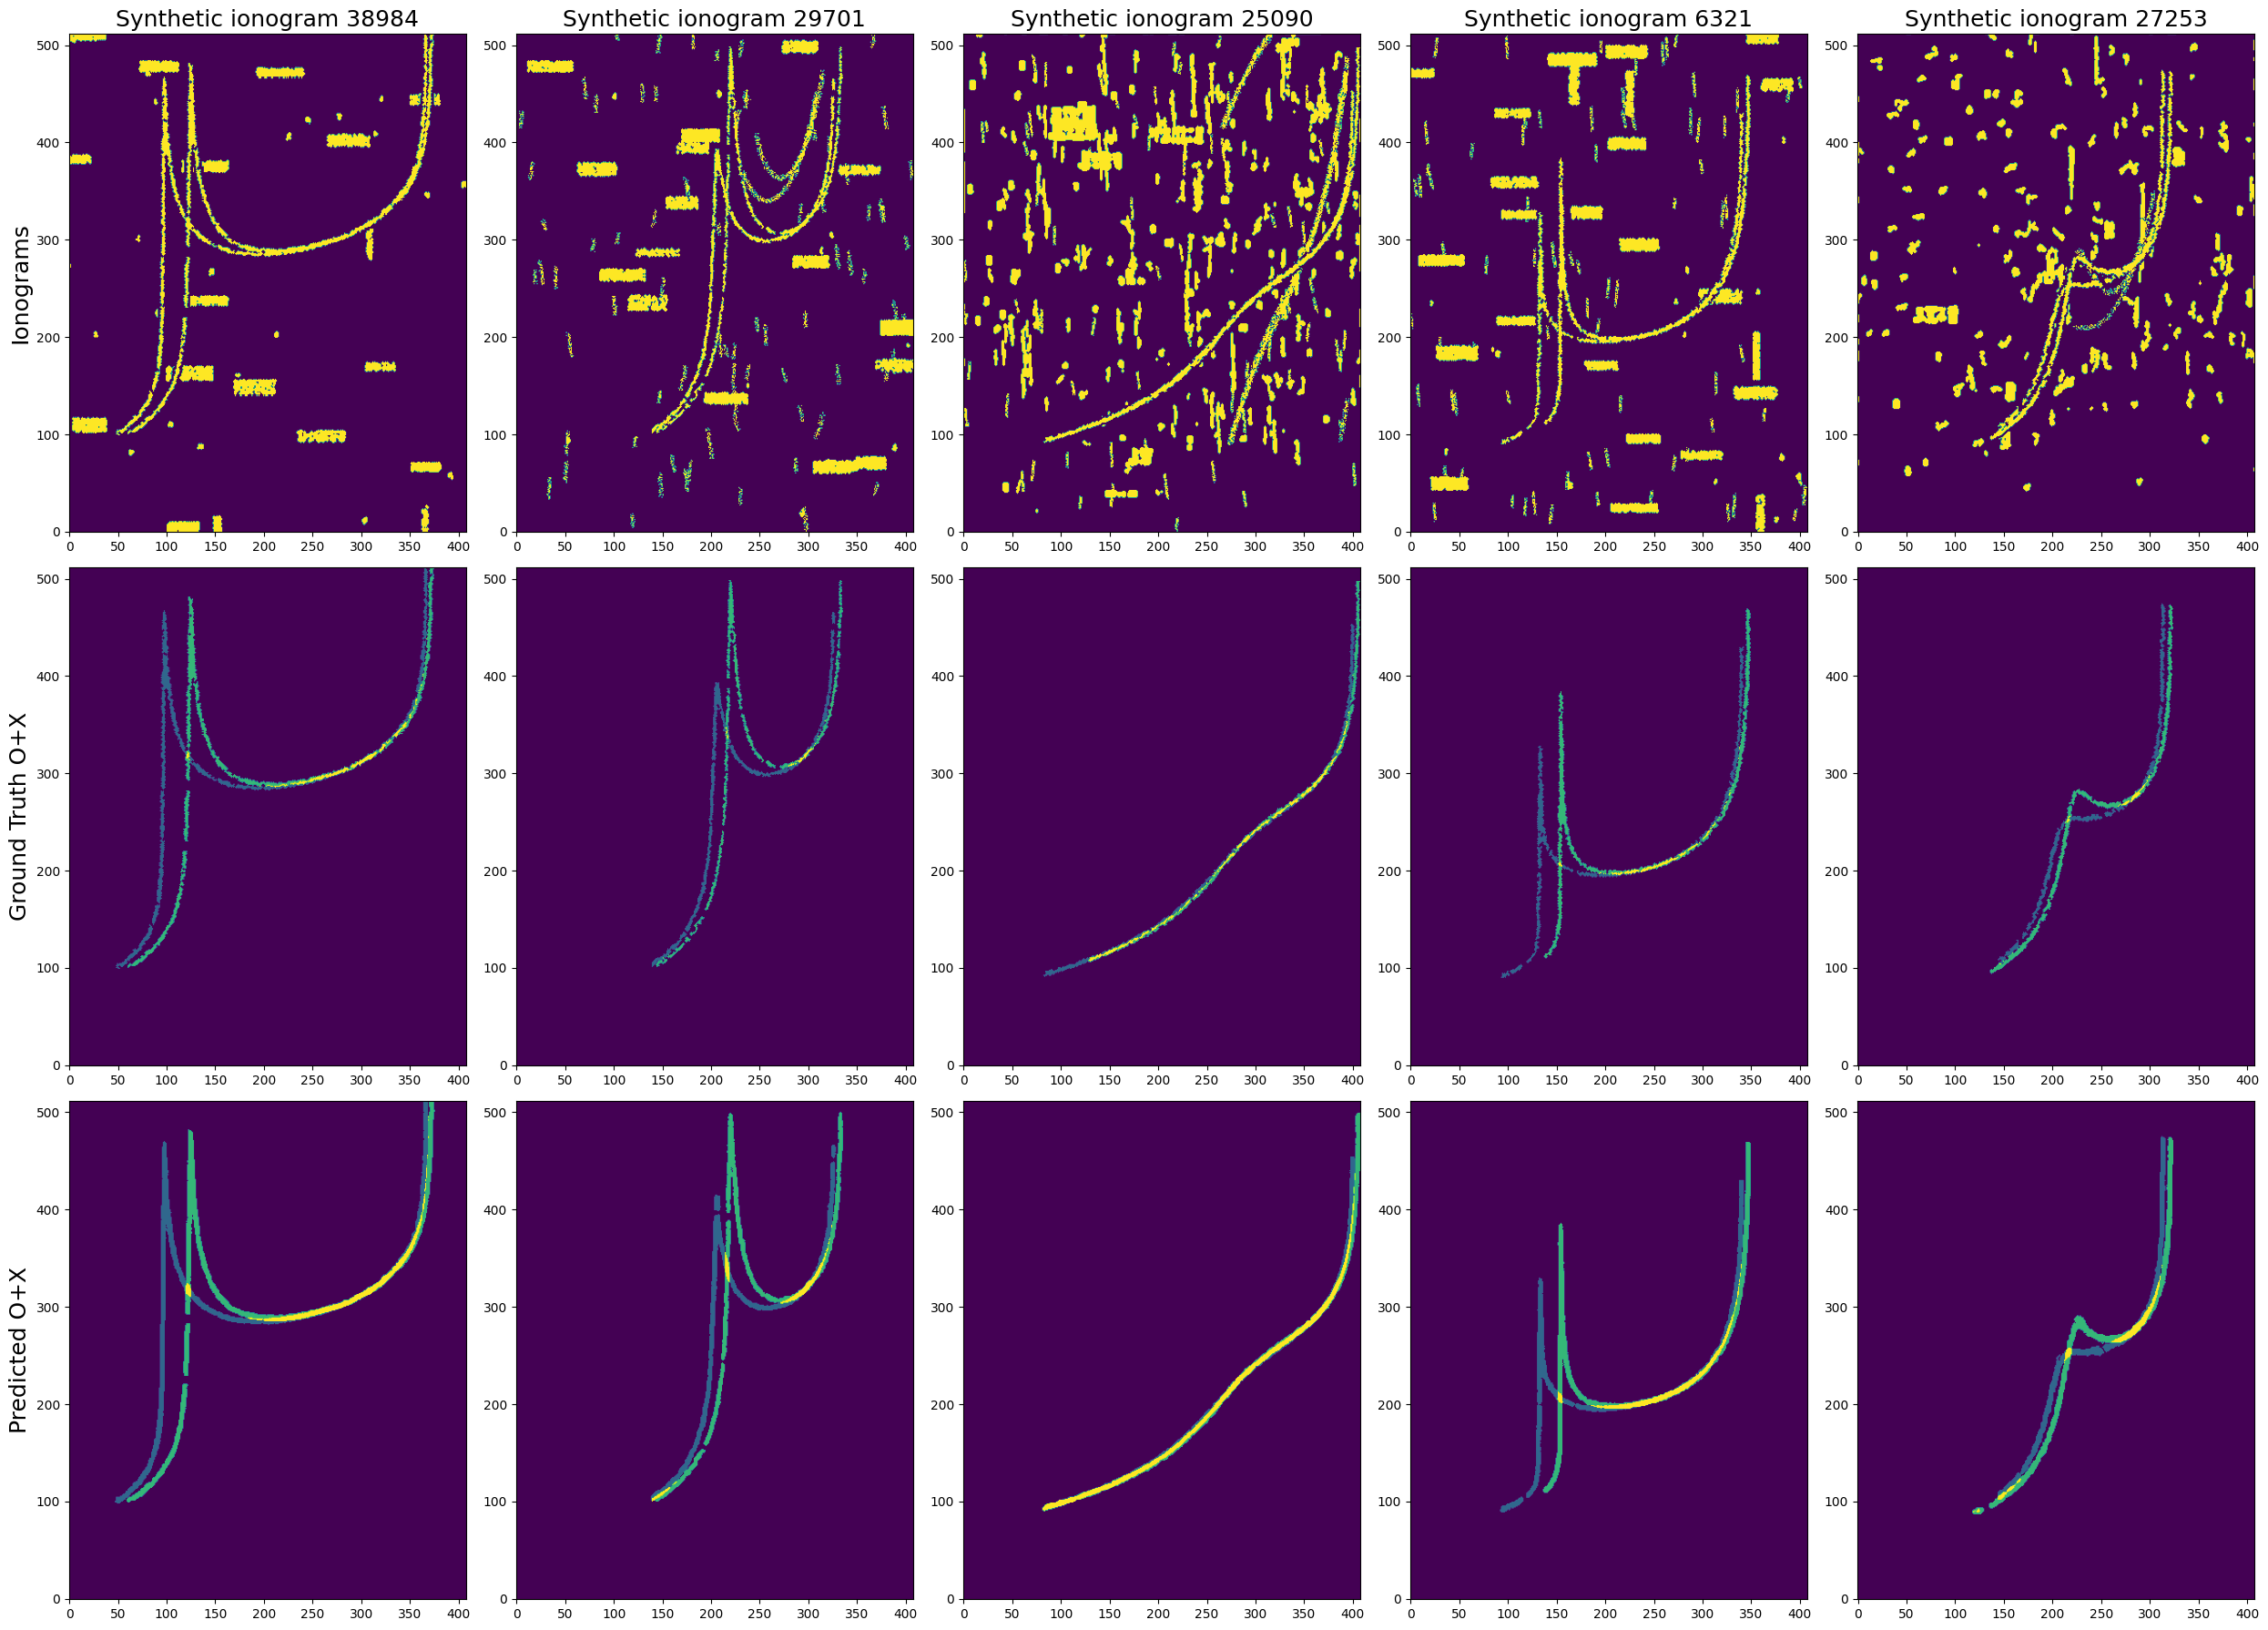

In [68]:
dbcefloss = DBCEF()

for ii, data in enumerate(val_loader, 0):
    inputs, labels, id = data['image'], data['mask'], data['filename']
    print(inputs.size(), labels.size())
    inputs, labels = inputs.to(device), labels.to(device)
    outputs = model(inputs)                
    loss = dbcefloss(outputs[:,0:2,:,:], labels[:,0,:,:]) + dbcefloss(outputs[:,2:4,:,:], labels[:,1,:,:])
    # loss = dbcefloss(outputs[:,0:2,:,:], torch.logical_or(labels[:,0,:,:],labels[:,1,:,:]).long())
    val_loss = loss.item()
    # del inputs; del labels
    break

img = inputs.permute((0, 2, 3, 1)).cpu().numpy()
gt = labels.permute((0, 2, 3, 1)).cpu().numpy()
result = outputs.detach().cpu().numpy()
resulto = result[:,0:2,:,:].argmax(axis=1)
resultx = result[:,2:4,:,:].argmax(axis=1)
print(result.shape)

fig, axs = plt.subplots(ncols=5, nrows=3, figsize=(25, 18))
for idx, ax_i in enumerate(axs.T):
    ax = ax_i[0]
    ax.set_title(f'Synthetic ionogram {id[idx]}',fontdict={'size':'18'})
    ax.imshow((img[idx]),aspect='equal' ,origin = 'lower')
    if idx == 0: ax.set_ylabel('Ionograms',fontdict={'size':'18'})
    ax.axis('on')
    ax = ax_i[1]
    ax.imshow((gt[idx,:,:,0]+2*gt[idx,:,:,1]), aspect='equal', origin = 'lower')
    ax.axis('on')
    if idx == 0: ax.set_ylabel('Ground Truth O+X',fontdict={'size':'18'})
    # ax = ax_i[2]
    # ax.imshow((gt[idx,:,:,1]), aspect='equal', origin = 'lower')
    # ax.axis('off')
    # ax.set_ylabel('Ground Truth X')
    ax = ax_i[2]
    ax.imshow(resulto[idx]+2*resultx[idx], aspect='equal', origin = 'lower')
    ax.axis('on')
    if idx == 0: ax.set_ylabel('Predicted O+X',fontdict={'size':'18'})
    # ax = ax_i[4]
    # ax.imshow(resultx[idx], aspect='equal', origin = 'lower')
    # ax.axis('off')
    # ax.set_ylabel('Predicted X')
fig.tight_layout()

/tmp/ipykernel_219268/1023615833.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  savedfile1 = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_15_25000_loss1.0712.pth'

(0.01, 0.02)

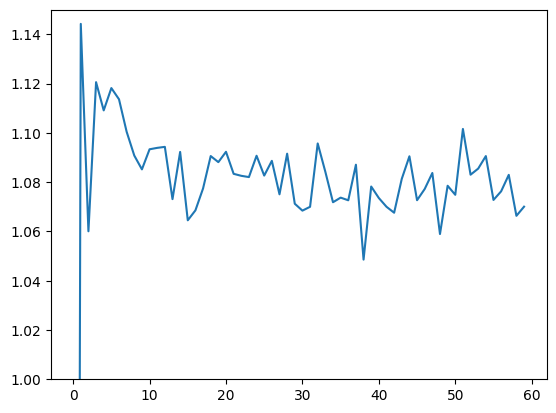

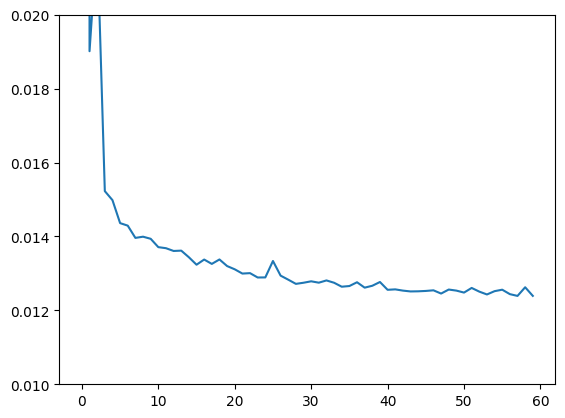

In [13]:
savedfile1 = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_15_25000_loss1.0712.pth')
savedfile2 = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_30_25000_loss1.0700.pth')
plt.figure()
plt.plot(savedfile1['test_loss']+savedfile2['test_loss'])
plt.ylim(1,1.15)

plt.figure()
plt.plot(savedfile1['val_loss']+savedfile2['val_loss'])
plt.ylim(0.01,0.02)

In [ ]:
# @torch.no_grad()
# def test_on_TOPHAT(model, epoch_num):    
with torch.inference_mode():
    img = []
    filename = []
    for _ in range(5):
        file = testfiles[np.random.randint(0,len(testfiles)-1)]
        filename += [file]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
        testimage = torch.from_numpy(testdata['mask_full']).float()
        testimage = testimage[None,None,:,:] if resize_tr == None else resize_tr(testimage[None,None,:,:])
        # testimage = torch.cat([testimage,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
        img += [testimage]
    
    img = torch.cat(img,dim=0)
    img = img.to('cuda')
    label = model(img)
    for i in range(5):
        img1,label1 = img[i],label[i]
        label1 = label1.squeeze().to('cpu')
        imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().numpy()
        # imgX = imgO
        imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().numpy()
        fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(20, 5))
        plt.title(f'epoch{epoch_num}_{filename[i]}')
        ax = axs[0]
        ax.imshow(img1.detach().cpu().numpy()[0], origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[1]
        ax.imshow(imgO, origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[2]
        ax.imshow(imgX, origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[3]
        imgX[imgO==1]=2
        ax.imshow(imgX, origin='lower', aspect = 'auto')
        ax.axis('off')

        # plt.savefig(f'testing_result/epoch{epoch_num}_{filename[i][:-4]}.png', bbox_inches='tight')
        # plt.close()
    del label; del img


In [ ]:
optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
dbcefloss = DBCEF()
dbcefloss = dbcefloss.to(device=device)
epcoh_elapsed = 0
losses = []
val_losses = []
test_losses = []

In [ ]:
epcoh_elapsed

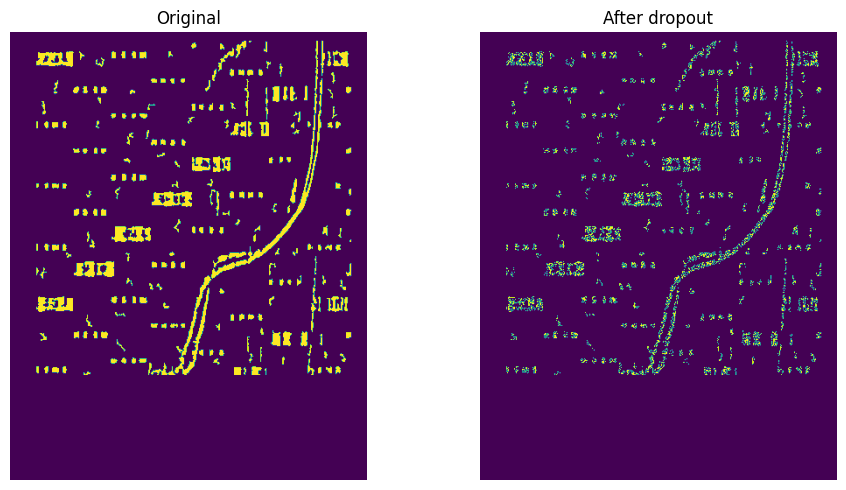

In [49]:
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(10, 5))
# for idx, ax_i in enumerate(axs.T):
target = test_dataset[10]
img = target["image"]
gt = target["mask"]
ax = axs[0]
img = img.permute((1, 2, 0)).numpy()
ax.imshow((img),aspect='equal' ,origin = 'lower')
ax.set_title('Original')
ax.axis('off')
ax = axs[1]
xd = nn.functional.dropout(torch.from_numpy(img),p=0.5)
ax.imshow(xd.numpy(), aspect='equal', origin = 'lower')
ax.set_title('After dropout')
ax.axis('off')
fig.tight_layout()
fig.savefig('dropout',dpi=300,bbox_inches='tight')

In [ ]:
# fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(12, 4))
# ax = axs[0]
# ax.plot(np.arange(len(losses))*checkpoint_N,losses)
# ax.set_xlabel('Steps');ax.set_ylabel('Training loss')
# ax = axs[1]
# ax.plot(np.arange(len(val_losses))*checkpoint_N,val_losses)
# ax.set_xlabel('Steps');ax.set_ylabel('Val loss')
# ax = axs[2]
# ax.plot(np.arange(len(test_losses))*checkpoint_N,test_losses)
# ax.set_xlabel('Steps');ax.set_ylabel('Val loss')
# fig.savefig(f'losses.png', bbox_inches='tight')

In [6]:
model = UNet(n_channels=3, n_classes=4, bilinear=False)
model.load_state_dict(torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_10_10000.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): ReLU(inplace=True)
      (2): GroupNorm(64, 64, eps=1e-05, affine=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): ReLU(inplace=True)
      (5): GroupNorm(64, 64, eps=1e-05, affine=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): ReLU(inplace=True)
          (2): GroupNorm(128, 128, eps=1e-05, affine=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4): ReLU(inplace=True)
          (5): GroupNorm(128, 128, eps=1e-05, affine=True)
        )
      )
   

In [12]:
testing = np.load('ionogram_test_set_177.npy', allow_pickle=True, fix_imports=True)[()]


In [13]:
# Test on the HANDPICK test dataset
import numpy as np
import matplotlib.pyplot as plt
testdata = testing['all_images']
testfilename = testing['all_filenames']
model.eval()
# XX, YY = torch.meshgrid(torch.linspace(0,571,572,dtype=torch.float32),torch.linspace(0,571,572,dtype=torch.float32))
for ii in range(len(testdata)):
    testimage1 = torch.from_numpy(testdata[ii]) .float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])*128

    testimage1 = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    
    testimage1 = testimage1.to('cuda')
    label1 = model(testimage1)
    # print(label1.shape)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()
    
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
    plt.title(testfilename[ii])
    ax = axs[0]
    ax.imshow(testimage1.cpu().detach().squeeze()[0], origin='lower', aspect = 'auto')
    ax.axis('off')
    ax = axs[1]

    imgX[imgO==1]=2
    ax.imshow(imgX, origin='lower', aspect = 'auto')
    ax.axis('off')
    # break
    plt.savefig(f'testing_result/{ii}.png', bbox_inches='tight')
    plt.close()

(-0.5, 571.5, -0.5, 571.5)

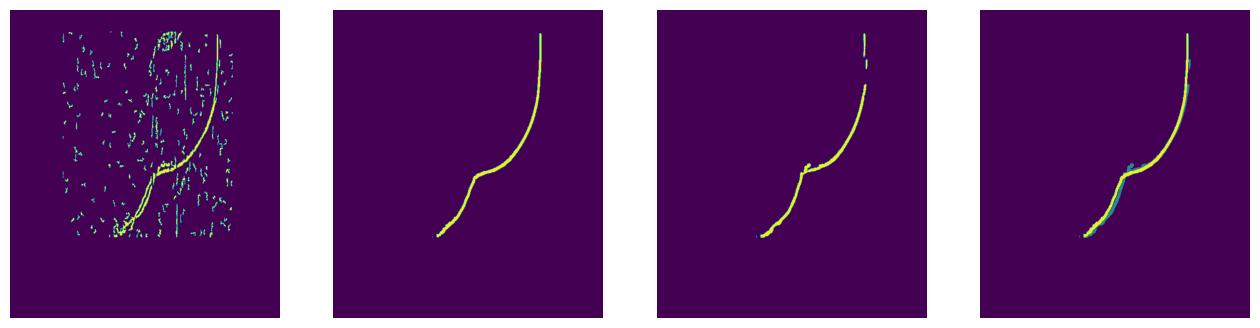

In [65]:
# model.train()
model.eval()
# target = train_dataset[np.random.randint(0,len(train_dataset)-1)]
target = test_dataset[np.random.randint(0,len(test_dataset)-1)]
# target = val_set[np.random.randint(0,len(val_set)-1)]
img = target["image"][None,:,:,:]
# img = torch.cat([img,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
img = img.to('cuda')
label1 = model(img)
label1 = label1.squeeze().to('cpu')
# transform = transforms.ToPILImage()
# img = transform(label1)
imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()

fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(16, 4))
ax = axs[0]
ax.imshow(img.cpu().detach().squeeze()[0], origin='lower', aspect = 'auto')
ax.axis('off')

ax = axs[1]
ax.imshow(imgO, origin='lower', aspect = 'auto')
ax.axis('off')

ax = axs[2]
ax.imshow(imgX, origin='lower', aspect = 'auto')
ax.axis('off')

imgX[imgO==1]=2
ax = axs[3]
ax.imshow(imgX, origin='lower', aspect = 'auto')
ax.axis('off')

# label0 = target["mask"][None,:,:,:]
# loss = dbcefloss(label1[None,0:2,:,:], label0[:,0,:,:]) + dbcefloss(label1[None,2:4,:,:], label0[:,1,:,:])
# print(loss.item())

In [6]:
model = UNet(n_channels=3, n_classes=4, bilinear=False)
model.load_state_dict(torch.load('checkpoints/dropout03/saved_model/'+'TOPHAT_checkpoint_epoch_10_10000.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): ReLU(inplace=True)
      (2): GroupNorm(64, 64, eps=1e-05, affine=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): ReLU(inplace=True)
      (5): GroupNorm(64, 64, eps=1e-05, affine=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): ReLU(inplace=True)
          (2): GroupNorm(128, 128, eps=1e-05, affine=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4): ReLU(inplace=True)
          (5): GroupNorm(128, 128, eps=1e-05, affine=True)
        )
      )
   

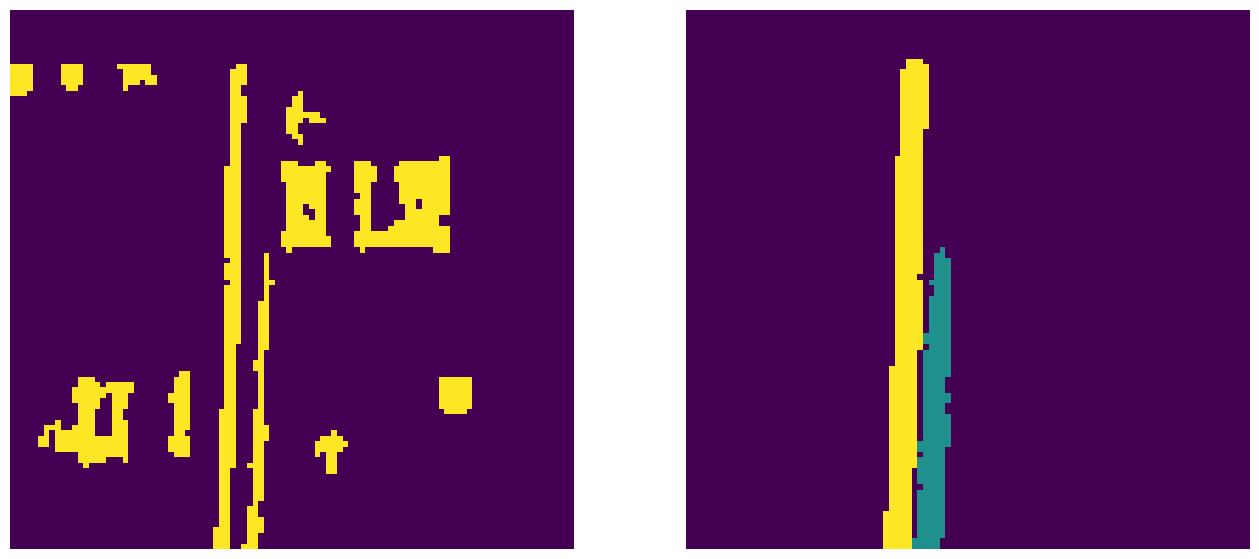

In [12]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
testim = torch.from_numpy(testim['mask_full']).float()
XX, YY = torch.meshgrid(torch.linspace(0,1,testim.size()[0],dtype=torch.float32),torch.linspace(0,1,testim.size()[1],dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:] #resize_tr(testimage1[None,None,:,:])
    img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()
    
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
    # plt.title(f'epoch{epoch_num}_{file}')
    ax = axs[0]
    ax.imshow(testimage1.detach().squeeze()[-100:,-100:], origin='lower', aspect = 'auto')
    ax.axis('off')
    ax = axs[1]

    imgX[imgO==1]=2
    ax.imshow(imgX[-100:,-100:], origin='lower', aspect = 'auto')
    ax.axis('off')
    # plt.savefig(f'testing_result/epoch{epoch_num}_{file[:-4]}.png', bbox_inches='tight')
    # plt.close()
